# Notebook 02 (v4) — Per-Component Parameter Analysis (cache-aware + skip-if-measured)

**Goal:** for each of the 20 vision-language models in the Phase-2 roster, count the number of parameters in each architectural component and surface the result inline so you can manually validate it against the legacy Sunita-1/2/3 numbers and against each model's reported figures.

**What's new in v4 (2026-05-22):**
* **Skip-if-already-measured** — re-running this notebook no longer re-loads models whose `outputs/measurements/<hf_id>.json` already has populated params for all expected components. The full 20-model run now finishes in seconds on the second invocation. Toggle via `SKIP_IF_MEASURED` in §1.
* **Upfront cache audit table** (§3) showing per-model: cache hit/miss, cache size on disk, prior-measurement status, expected fp16 footprint, and the predicted action (`SKIP` / `LOAD-CACHED` / `DOWNLOAD`). You see what's about to happen before you start.
* **Force-rerun list** — set `FORCE_RERUN = ['LLaVA-1.5-7B', ...]` in §1 to re-measure specific models even if their JSON exists.
* All v3 features carried over: schema-aware aggregation (Chameleon native_fused, Janus-Pro decoupled_vision), 5 figures, Runpod-only setup, hf_transfer soft-fallback.

**Inputs:**
* Existing per-model JSONs in `../outputs/measurements/` (v4 uses these as a cache; v3 ignored them).

**Outputs:**
* Per-model JSON records written/updated at `../outputs/measurements/<sanitized_hf_id>.json` (incremental merge).
* Verbose `.txt` logs in `../outputs/logs/<timestamp>_02_parameter_analysis_v4_nb__<hf_id>.txt` — only for models actually re-measured.
* `nb02_parameter_summary.csv`, `nb02_family_summary.csv`, `nb02_parameter_wide.csv` in `../outputs/measurements/`.
* 5 PNG figures in `../outputs/figures/nb02_*.png` (300 dpi).

**Compute:** CPU works; GPU helps only for faster model loading. No memory measurements here — those are in notebook 04.

**Runtime on Runpod L40/A100, warm cache, `SKIP_IF_MEASURED=True`, all 20 already measured:** ~5 s (just reads JSONs, builds tables + figures). First run cold: ~20-40 min (~250 GB download).

---
## 1. Setup (Runpod) + run-flags

In [1]:
# ===== Environment-specific flags =====
# Set to True on disk-constrained hosts (Colab ~235 GB) so each model's HF cache
# is deleted after measuring its params. Set to False on Runpod (1TB+) so
# subsequent notebooks (03 FLOPs, 04 memory) can reuse the cache.
CLEANUP_HF_CACHE_BETWEEN_MODELS = False

# Skip a model if its outputs/measurements/<hf_id>.json already has params
# for every component the extractor would produce. The downstream tables and
# figures still read from the per-model JSONs, so skipped models appear with
# their previously-measured values.
SKIP_IF_MEASURED = True

# Re-measure these specific models even if SKIP_IF_MEASURED is True.
# Use the model.name from MODELS (NOT the hf_id). Example:
#   FORCE_RERUN = ['LLaVA-1.5-7B', 'CLIP-ViT-L/14']
FORCE_RERUN = []

# Warn when free disk drops below this many GB. Aborts the loop if it goes lower.
DISK_FREE_GB_WARN = 30
DISK_FREE_GB_ABORT = 10

In [2]:
# %%capture
# !pip install -q -r ../requirements.txt

In [4]:
# Set HF_TOKEN here if not already in env. Required for gated models
# (LLaMA / IDEFICS / Pixtral / Llama-3.2-Vision / Chameleon / InstructBLIP).
import os
# os.environ['HF_TOKEN'] = '<your Hugging Face token>'  # uncomment + paste your token if needed
assert os.environ.get('HF_TOKEN'), 'HF_TOKEN not set — gated models will fail to download'

# Runpod's PyTorch image sets HF_HUB_ENABLE_HF_TRANSFER=1 for faster downloads,
# which requires the `hf_transfer` Python package. If it's missing, every
# from_pretrained() call errors out. Soft-detect and disable fast-transfer.
if os.environ.get('HF_HUB_ENABLE_HF_TRANSFER') == '1':
    try:
        import hf_transfer  # noqa: F401
        print('✓ hf_transfer available — fast downloads ENABLED')
    except ImportError:
        os.environ['HF_HUB_ENABLE_HF_TRANSFER'] = '0'
        print('⚠ HF_HUB_ENABLE_HF_TRANSFER=1 but hf_transfer package not installed.')
        print('  Disabled fast-transfer for this session (downloads will be slower).')
        print('  To re-enable: pip install hf_transfer  --break-system-packages')
else:
    print('hf_transfer fast-download not requested by env')

✓ hf_transfer available — fast downloads ENABLED


In [5]:
import sys, shutil
from pathlib import Path

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

HF_HOME = Path(os.environ.get('HF_HOME', str(Path.home() / '.cache' / 'huggingface'))).expanduser()
HF_CACHE = HF_HOME / 'hub'

def free_disk_gb(p='/'):
    s = shutil.disk_usage(p)
    return s.free / 1e9, s.total / 1e9

free_gb, total_gb = free_disk_gb()
print(f'Working dir:        {NB_DIR}')
print(f'code_active dir:    {CODE_ACTIVE}')
print(f'vlm_audit:          {CODE_ACTIVE / "vlm_audit"}')
print(f'HF_HOME (env):      {os.environ.get("HF_HOME", "<not set, using default>")}')
print(f'HF cache dir:       {HF_CACHE}')
print(f'Measurement dir:    {MEASUREMENT_DIR}')
print(f'Disk:               {free_gb:.1f} GB free / {total_gb:.1f} GB total ({100*free_gb/total_gb:.1f}% free)')
print()
print(f'Run flags:')
print(f'  SKIP_IF_MEASURED:                {SKIP_IF_MEASURED}')
print(f'  FORCE_RERUN:                     {FORCE_RERUN}')
print(f'  CLEANUP_HF_CACHE_BETWEEN_MODELS: {CLEANUP_HF_CACHE_BETWEEN_MODELS}')

Working dir:        /workspace/code_active/notebooks
code_active dir:    /workspace/code_active
vlm_audit:          /workspace/code_active/vlm_audit
HF_HOME (env):      /workspace/.cache/huggingface/
HF cache dir:       /workspace/.cache/huggingface/hub
Measurement dir:    /workspace/code_active/outputs/measurements
Disk:               51.3 GB free / 53.7 GB total (95.5% free)

Run flags:
  SKIP_IF_MEASURED:                True
  FORCE_RERUN:                     []
  CLEANUP_HF_CACHE_BETWEEN_MODELS: False


In [6]:
import pandas as pd
import numpy as np
import torch
import time
import traceback
import gc
import json
import matplotlib.pyplot as plt

from vlm_audit import (
    MODELS, get_model_list, count_params,
    extract_components, compute_trainable_from_policy,
    run_full_audit, InputConfig,
)
from vlm_audit.runner import _load_model, _resolve_hf_class, load_existing_record
from vlm_audit.components import (
    freezing_policy_hint, trainable_components_for_family,
    COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES,
)
from vlm_audit.logging_utils import sanitize_for_filename
from vlm_audit.schema import ModelRecord

print(f'PyTorch:        {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU:            {torch.cuda.get_device_name(0)}')
print(f'Models in roster: {len(MODELS)}')

PyTorch:        2.8.0+cu128
CUDA available: True
GPU:            NVIDIA A100-SXM4-80GB
Models in roster: 20


---
## 2. Schema awareness — three families of component layouts

(carried over from v3) The 20 models fall into three component schemas:

| Schema | Models | Component keys |
|---|---|---|
| `standard_vflh` | 18 of 20 | `vision`, `fusion`, `language`, `head` |
| `native_fused` | Chameleon-7B | `fused_transformer`, `embeddings`, `head` (V/F/L all None) |
| `decoupled_vision` | Janus-Pro-7B | `vision_und`, `vision_gen`, `fusion`, `language`, `head` |

Aggregation helpers below treat all schemas correctly.

In [7]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '_total') -> pd.Series:
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

# Schema → expected component names (for the skip-if-measured check)
EXPECTED_COMPONENTS = {
    'standard_vflh':     ['vision', 'fusion', 'language', 'head'],
    'native_fused':      ['head', 'fused_transformer', 'embeddings'],
    'decoupled_vision':  ['vision', 'fusion', 'language', 'head', 'vision_und', 'vision_gen'],
}

print('schema_for(), safe_sum(), EXPECTED_COMPONENTS ready.')

schema_for(), safe_sum(), EXPECTED_COMPONENTS ready.


---
## 3. Pre-run audit — what's cached and what's measured?

Before the main loop runs, scan every model and answer four questions:
1. Is it in the **HF cache**? (model weights already downloaded)
2. Does its **measurement JSON** exist? (a previous run wrote params)
3. Are **all expected components** populated in the JSON?
4. What **action** will the main loop take? (`SKIP` / `LOAD-CACHED` / `DOWNLOAD`)

**`SKIP`** = don't load the model at all; just read the existing JSON.
**`LOAD-CACHED`** = load model weights from disk (no network), re-run params + overwrite JSON.
**`DOWNLOAD`** = fetch weights from HF Hub, then load + measure.

In [8]:
def hf_cache_size_gb(hf_id: str) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return 0.0
    total = 0
    for p in cache_subdir.rglob('*'):
        if p.is_file() and not p.is_symlink():
            try:
                total += p.stat().st_size
            except Exception:
                pass
    return total / 1e9

def is_in_hf_cache(hf_id: str, min_gb: float = 0.1) -> bool:
    return hf_cache_size_gb(hf_id) > min_gb

def measurement_json_path(hf_id: str) -> Path:
    return MEASUREMENT_DIR / f'{sanitize_for_filename(hf_id)}.json'

def has_measured_params(spec, expected_comps, min_params_per_comp: int = 0) -> bool:
    """True iff JSON exists AND has non-None params_total for every expected component."""
    p = measurement_json_path(spec.hf_id)
    if not p.exists():
        return False
    try:
        data = json.loads(p.read_text(encoding='utf-8'))
    except Exception:
        return False
    comps = data.get('components', {})
    for cname in expected_comps:
        c = comps.get(cname)
        if c is None:
            return False
        pt = c.get('params_total')
        # head can legitimately be 0 for CLIP-style. We accept any non-None.
        if pt is None:
            return False
    return True

def planned_action(spec) -> str:
    sch = schema_for(spec.family)
    expected = EXPECTED_COMPONENTS[sch]
    if spec.name in FORCE_RERUN:
        return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'
    if SKIP_IF_MEASURED and has_measured_params(spec, expected):
        return 'SKIP'
    return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'

In [10]:
# Build the pre-run audit table
rows = []
for spec in MODELS:
    sch = schema_for(spec.family)
    expected = EXPECTED_COMPONENTS[sch]
    json_path = measurement_json_path(spec.hf_id)
    cache_size = hf_cache_size_gb(spec.hf_id)
    has_meas = has_measured_params(spec, expected)
    rows.append({
        'name': spec.name,
        'schema': sch,
        'hf_id': spec.hf_id,
        'fp16_GB': spec.fits_in_gb_fp16,
        'cache_GB': round(cache_size, 2),
        'cached': cache_size > 0.1,
        'json_exists': json_path.exists(),
        'json_complete': has_meas,
        'force_rerun': spec.name in FORCE_RERUN,
        'action': planned_action(spec),
    })
audit_df = pd.DataFrame(rows)

# Print summary counts
act = audit_df['action'].value_counts().to_dict()
print(f'Planned actions across {len(audit_df)} models:')
for k in ['SKIP', 'LOAD-CACHED', 'DOWNLOAD']:
    print(f'  {k:13s}: {act.get(k, 0):2d}')
print()
total_cache_GB = audit_df['cache_GB'].sum()
to_download_GB = audit_df.loc[audit_df['action'] == 'DOWNLOAD', 'fp16_GB'].sum()
print(f'Total HF cache on disk:     {total_cache_GB:.1f} GB')
print(f'Models with measurement JSON: {audit_df["json_exists"].sum()}/{len(audit_df)}')
print(f'Models with complete params:  {audit_df["json_complete"].sum()}/{len(audit_df)}')
print(f'Estimated download required:  ~{to_download_GB:.1f} GB (fp16 footprint of DOWNLOAD models)')
print()
audit_df[['name','schema','fp16_GB','cache_GB','cached','json_complete','force_rerun','action']]

Planned actions across 20 models:
  SKIP         : 13
  LOAD-CACHED  :  2
  DOWNLOAD     :  5

Total HF cache on disk:     233.7 GB
Models with measurement JSON: 20/20
Models with complete params:  13/20
Estimated download required:  ~96.0 GB (fp16 footprint of DOWNLOAD models)



,name,schema,fp16_GB,cache_GB,cached,json_complete,force_rerun,action
0,CLIP-ViT-L/14,standard_vflh,1.0,1.71,True,True,False,SKIP
1,SigLIP-L/16,standard_vflh,1.5,2.61,True,True,False,SKIP
2,BLIP-large,standard_vflh,1.0,1.88,True,True,False,SKIP
3,BLIP-2-OPT-2.7B,standard_vflh,7.0,14.98,True,True,False,SKIP
4,InstructBLIP-Vicuna-7B,standard_vflh,17.0,31.66,True,True,False,SKIP
5,LLaVA-1.5-7B,standard_vflh,16.0,14.13,True,True,False,SKIP
6,LLaVA-NeXT-7B,standard_vflh,16.0,15.13,True,True,False,SKIP
7,IDEFICS-9B,standard_vflh,18.0,35.72,True,True,False,SKIP
8,Idefics2-8B,standard_vflh,16.0,33.61,True,True,False,SKIP
9,ViLT-B/32,standard_vflh,0.5,0.94,True,True,False,SKIP


**Interpretation:**
* If you see all 20 rows with `action=SKIP` → great, this notebook will finish in seconds. Skip to §8 master table to see your results.
* `action=LOAD-CACHED` → weights are on disk, model loads in 5-30 s. The audit re-measures params and overwrites the JSON.
* `action=DOWNLOAD` → expect ~1-5 min per model for the first run. After the first run, the model becomes LOAD-CACHED.
* If `cached=True` but `json_complete=False` → the model is downloaded but never measured (e.g. crashed last run). The main loop will load + measure.
* If a model is in FORCE_RERUN, action is at least LOAD-CACHED — useful when `vlm_audit/runner.py` or extractor logic was patched and you want to recompute that one row.

---
## 4. Inspect the model roster

In [11]:
roster_df = pd.DataFrame([
    {
        'name':           m.name,
        'family':         m.family,
        'schema':         schema_for(m.family),
        'year':           m.release_year,
        'fp16_GB':        m.fits_in_gb_fp16,
        'native_HW':      f'{m.native_image_hw[0]}x{m.native_image_hw[1]}',
        'recent_gen':     m.recent_gen,
        'is_moe':         m.is_moe,
        'trust_remote':   m.requires_trust_remote_code,
        'hf_id':          m.hf_id,
    }
    for m in MODELS
])
print(f'Total models: {len(roster_df)}')
print(f'Families:     {sorted(roster_df.family.unique())} ({len(roster_df.family.unique())} families)')
print(f'Schemas:      {roster_df.schema.value_counts().to_dict()}')
print(f'Recent-gen models (2024+): {int(roster_df.recent_gen.sum())}')
print(f'Total fp16 footprint sum: {roster_df["fp16_GB"].sum():.1f} GB')
roster_df

Total models: 20
Families:     ['adapter_llm', 'adapter_llm_own_encoder', 'bridge_module', 'bridge_module_adapter_llm', 'bridge_module_precursor', 'cross_attention_llm', 'dual_encoder_contrastive', 'dynamic_tile_adapter_llm', 'moe_adapter_llm', 'native_decoupled_encoder', 'native_early_fusion', 'perceiver_adapter_llm', 'single_stream_fused'] (13 families)
Schemas:      {'standard_vflh': 18, 'native_fused': 1, 'decoupled_vision': 1}
Recent-gen models (2024+): 12
Total fp16 footprint sum: 266.5 GB


,name,family,schema,year,fp16_GB,native_HW,recent_gen,is_moe,trust_remote,hf_id
0,CLIP-ViT-L/14,dual_encoder_contrastive,standard_vflh,2021,1.0,224x224,False,False,False,openai/clip-vit-large-patch14
1,SigLIP-L/16,dual_encoder_contrastive,standard_vflh,2023,1.5,384x384,False,False,False,google/siglip-large-patch16-384
2,BLIP-large,bridge_module_precursor,standard_vflh,2022,1.0,384x384,False,False,False,Salesforce/blip-image-captioning-large
3,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,7.0,224x224,False,False,False,Salesforce/blip2-opt-2.7b
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,17.0,224x224,False,False,False,Salesforce/instructblip-vicuna-7b
5,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,16.0,336x336,False,False,False,llava-hf/llava-1.5-7b-hf
6,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,16.0,336x336,True,False,False,llava-hf/llava-v1.6-mistral-7b-hf
7,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,18.0,224x224,False,False,False,HuggingFaceM4/idefics-9b
8,Idefics2-8B,perceiver_adapter_llm,standard_vflh,2024,16.0,224x224,True,False,False,HuggingFaceM4/idefics2-8b
9,ViLT-B/32,single_stream_fused,standard_vflh,2021,0.5,384x384,False,False,False,dandelin/vilt-b32-finetuned-vqa


---
## 5. Smoke test — CLIP-ViT-L/14 (Sunita-1 anchor)

Validate the pipeline on one known-good model against the legacy Sunita-1 cell 12 anchor:
* `vision_model`:  303,179,776 params
* `text_model`:    123,060,480 params
* projection:        1,376,256 params

If CLIP is already measured AND SKIP_IF_MEASURED is True, this just reads the JSON. Otherwise it loads + measures.

In [12]:
clip_spec = next(m for m in MODELS if m.name == 'CLIP-ViT-L/14')
print(f'CLIP audit plan: {planned_action(clip_spec)}')

if planned_action(clip_spec) == 'SKIP':
    rec = load_existing_record(clip_spec, str(MEASUREMENT_DIR))
    print(f'Loaded from JSON ({len(rec.components)} components)')
else:
    t0 = time.time()
    rec = run_full_audit(
        clip_spec, metrics={'params'},
        measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
        notebook_label='02_parameter_analysis_v4_nb',
    )
    print(f'Audited in {time.time()-t0:.1f}s')

CLIP audit plan: SKIP
Loaded from JSON (4 components)


In [13]:
clip_df = pd.DataFrame([
    {
        'component':         c.name,
        'params_total':      c.params_total,
        'params_total_M':    round((c.params_total or 0) / 1e6, 2),
        'params_trainable':  c.params_trainable,
        'trainable_frac':    round((c.params_trainable or 0) / max(c.params_total or 1, 1), 3),
        'notes':             c.notes,
    }
    for c in rec.components.values()
])
clip_df

,component,params_total,params_total_M,params_trainable,trainable_frac,notes
0,head,0,0.00,0,0.0,absent
1,fusion,1376256,1.38,1376256,1.0,
2,vision,303179776,303.18,303179776,1.0,
3,language,123060480,123.06,123060480,1.0,


In [14]:
EXPECTED = {
    'vision':   303_179_776,
    'language': 123_060_480,
    'fusion':     1_376_256,
}
ok = True
for cname, expected in EXPECTED.items():
    got = rec.components.get(cname)
    got_val = (got.params_total or 0) if got else 0
    delta = got_val - expected
    status = '✓' if delta == 0 else f'✗ (off by {delta:+,})'
    print(f'  {cname:10s}: expected {expected:>12,}  got {got_val:>12,}  {status}')
    if delta != 0:
        ok = False
assert ok, 'CLIP-L params do not match legacy Sunita-1 — extractor may be broken or JSON stale!'
print('\n✓ CLIP-L params match Sunita-1 cell 12 exactly.')

  vision    : expected  303,179,776  got  303,179,776  ✓
  language  : expected  123,060,480  got  123,060,480  ✓
  fusion    : expected    1,376,256  got    1,376,256  ✓

✓ CLIP-L params match Sunita-1 cell 12 exactly.


---
## 6. Main loop — for each model, SKIP / LOAD-CACHED / DOWNLOAD

The decision rule per model:
1. **`SKIP`**: just `load_existing_record(...)` from disk. ~10 ms.
2. Else: call `run_full_audit(...)` with `metrics={'params'}` (downloads if not cached, otherwise loads from cache).

Each model's outcome ends up in the `results` list (so downstream cells work uniformly regardless of SKIP / measurement).

Per-model output:
* `[i/N] <name>` with action label
* On SKIP: shows component count + total params from the existing JSON
* On LOAD-CACHED / DOWNLOAD: schema-aware inline interpretation of param allocation
* Failure handling: any exception goes into `failures` list, run continues

In [15]:
def cleanup_hf_cache_for(hf_id: str, log=True) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return 0.0
    sz = hf_cache_size_gb(hf_id)
    shutil.rmtree(cache_subdir, ignore_errors=True)
    if log:
        print(f'      [cleanup] removed {sz:.2f} GB of cache for {hf_id}')
    return sz

def interpret_allocation(rec, schema: str) -> str:
    comps = rec.components
    def g(name):
        c = comps.get(name)
        return (c.params_total if c else 0) or 0
    if schema == 'native_fused':
        fused = g('fused_transformer'); emb = g('embeddings'); head = g('head')
        total = fused + emb + head
        if total == 0:
            return '      [interpret] native fused (no decomposition)'
        return (f'      [interpret] native EARLY FUSION → {fused/1e6:.0f}M shared transformer + '
                f'{emb/1e6:.0f}M embeddings + {head/1e6:.0f}M head (total {total/1e9:.2f}B)')
    if schema == 'decoupled_vision':
        v_und = g('vision_und'); v_gen = g('vision_gen'); l = g('language'); h = g('head')
        total = v_und + v_gen + l + h + g('fusion')
        return (f'      [interpret] DECOUPLED vision → understanding {v_und/1e6:.0f}M + '
                f'generation {v_gen/1e6:.0f}M + language {l/1e9:.2f}B; total {total/1e9:.2f}B')
    v, f, l, h = g('vision'), g('fusion'), g('language'), g('head')
    total = v + f + l + h
    if total == 0:
        return '      [interpret] no decomposition'
    v_pct = 100 * v / total; f_pct = 100 * f / total; l_pct = 100 * l / total
    if v_pct > 50: dom = 'vision-dominant'
    elif l_pct > 70: dom = 'language-dominant'
    elif 0.4 < v / max(l, 1) < 2.5: dom = 'roughly balanced'
    else: dom = 'mixed'
    trainable_total = sum((c.params_trainable or 0) for c in comps.values())
    train_pct = 100 * trainable_total / max(total + h, 1)
    return (f'      [interpret] {v_pct:.1f}% vision · {f_pct:.1f}% fusion · {l_pct:.1f}% language '
            f'→ {dom}; {train_pct:.1f}% trainable')

In [16]:
# Choose what to run:
#   MODELS         — all 20
#   MODELS[:3]     — smoke test
#   MODELS[13:]    — resume from a specific index
TARGETS = MODELS

results = []   # rows for the master DataFrame
failures = []
skipped = []   # names of models that were SKIP-ped
cleanup_total_gb = 0.0

for i, spec in enumerate(TARGETS, 1):
    free_gb_before, _ = free_disk_gb()
    sch = schema_for(spec.family)
    action = planned_action(spec)
    cache_gb_before = hf_cache_size_gb(spec.hf_id)
    print(f'\n[{i}/{len(TARGETS)}] {spec.name:30s} schema={sch:18s} action={action:11s} disk_free={free_gb_before:.1f} GB cache_now={cache_gb_before:.1f}GB')

    if free_gb_before < DISK_FREE_GB_ABORT and action == 'DOWNLOAD':
        print(f'    ⛔ disk free < {DISK_FREE_GB_ABORT} GB — ABORTING')
        failures.append({'name': spec.name, 'error': f'aborted: disk_free={free_gb_before:.1f} GB'})
        break

    t0 = time.time()
    try:
        if action == 'SKIP':
            rec = load_existing_record(spec, str(MEASUREMENT_DIR))
            if rec is None or not rec.components:
                # safety net: JSON disappeared between audit and now
                rec = run_full_audit(
                    spec, metrics={'params'},
                    measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                    notebook_label='02_parameter_analysis_v4_nb',
                )
            else:
                skipped.append(spec.name)
        else:
            rec = run_full_audit(
                spec, metrics={'params'},
                measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                notebook_label='02_parameter_analysis_v4_nb',
            )
        row = {'name': spec.name, 'family': spec.family, 'schema': sch, 'year': spec.release_year}
        for cname, c in rec.components.items():
            row[f'{cname}_total'] = c.params_total or 0
            row[f'{cname}_trainable'] = c.params_trainable or 0
        results.append(row)
        total_M = sum((c.params_total or 0) for c in rec.components.values()) / 1e6
        elapsed = time.time() - t0
        if action == 'SKIP':
            print(f'    SKIP  total={total_M:.2f}M params  (read from JSON in {elapsed*1000:.0f}ms)')
        else:
            print(f'    OK    total={total_M:.2f}M params  ({elapsed:.1f}s)')
        print(interpret_allocation(rec, sch))
        if action != 'SKIP' and CLEANUP_HF_CACHE_BETWEEN_MODELS:
            cleanup_total_gb += cleanup_hf_cache_for(spec.hf_id, log=True)
    except Exception as e:
        tb = traceback.format_exc()
        failures.append({
            'name': spec.name, 'family': spec.family,
            'error': f'{type(e).__name__}: {e}',
            'traceback_excerpt': '\n'.join(tb.splitlines()[-5:]),
        })
        print(f'    FAILED  {type(e).__name__}: {e}')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f'\n=== Finished: {len(results)} succeeded ({len(skipped)} skipped, {len(results)-len(skipped)} measured), {len(failures)} failed ===')
if CLEANUP_HF_CACHE_BETWEEN_MODELS:
    print(f'  Cleaned up {cleanup_total_gb:.1f} GB of HF cache during run')
free_gb_after, _ = free_disk_gb()
print(f'  Disk free now: {free_gb_after:.1f} GB')


[1/20] CLIP-ViT-L/14                  schema=standard_vflh      action=SKIP        disk_free=51.3 GB cache_now=1.7GB
    SKIP  total=427.62M params  (read from JSON in 2ms)
      [interpret] 70.9% vision · 0.3% fusion · 28.8% language → vision-dominant; 100.0% trainable

[2/20] SigLIP-L/16                    schema=standard_vflh      action=SKIP        disk_free=51.3 GB cache_now=2.6GB
    SKIP  total=652.48M params  (read from JSON in 1ms)
      [interpret] 48.5% vision · 0.0% fusion · 51.5% language → roughly balanced; 100.0% trainable

[3/20] BLIP-large                     schema=standard_vflh      action=SKIP        disk_free=51.3 GB cache_now=1.9GB
    SKIP  total=446.29M params  (read from JSON in 2ms)
      [interpret] 68.0% vision · 0.0% fusion · 32.0% language → vision-dominant; 100.0% trainable

[4/20] BLIP-2-OPT-2.7B                schema=standard_vflh      action=SKIP        disk_free=51.3 GB cache_now=15.0GB
    SKIP  total=3744.74M params  (read from JSON in 2ms)
      [

model-00004-of-00005.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

model-00005-of-00005.safetensors:   0%|          | 0.00/1.09G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

    OK    total=8335.95M params  (60.5s)
      [interpret] 8.1% vision · 0.5% fusion · 84.8% language → language-dominant; 93.9% trainable

[13/20] Qwen2.5-VL-7B-Instruct         schema=standard_vflh      action=DOWNLOAD    disk_free=51.3 GB cache_now=0.0GB


... (61 outputs left out)

model-00005-of-00005.safetensors:   0%|          | 0.00/1.47G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

    OK    total=10670.22M params  (132.7s)
      [interpret] 8.1% vision · 0.3% fusion · 86.7% language → language-dominant; 5.0% trainable

[18/20] DeepSeek-VL2-Small             schema=standard_vflh      action=SKIP        disk_free=51.3 GB cache_now=32.3GB
    SKIP  total=16148.35M params  (read from JSON in 2ms)
      [interpret] 2.7% vision · 0.1% fusion · 97.3% language → language-dominant; 97.3% trainable

[19/20] Chameleon-7B                   schema=native_fused       action=SKIP        disk_free=51.3 GB cache_now=14.1GB
    SKIP  total=7311.53M params  (read from JSON in 2ms)
      [interpret] native EARLY FUSION → 6775M shared transformer + 268M embeddings + 268M head (total 7.31B)

[20/20] Janus-Pro-7B                   schema=decoupled_vision   action=SKIP        disk_free=51.3 GB cache_now=14.8GB
    SKIP  total=7635.86M params  (read from JSON in 2ms)
      [interpret] DECOUPLED vision → understanding 316M + generation 72M + language 6.91B; total 7.32B

=== Finished: 20 

---
## 7. Master parameter table (schema-aware)

Same logic as v3. Now reads from the merged `results` list (which mixes SKIP-loaded and freshly-measured rows seamlessly).

In [17]:
if not results:
    print('No successful results — see failures below.')
    params_df = pd.DataFrame()
else:
    params_df = pd.DataFrame(results)
    params_df['total_M']           = safe_sum(params_df, EXTENDED_PARTS, '_total')     / 1e6
    params_df['trainable_total_M'] = safe_sum(params_df, EXTENDED_PARTS, '_trainable') / 1e6
    params_df['vision_like_M']     = safe_sum(params_df, VISION_LIKE_PARTS, '_total')  / 1e6
    params_df['language_like_M']   = safe_sum(params_df, LANGUAGE_LIKE_PARTS, '_total')/ 1e6
    params_df['fusion_M']          = safe_sum(params_df, ['fusion'], '_total')         / 1e6
    params_df['head_M']            = safe_sum(params_df, ['head'], '_total')           / 1e6
    denom = (params_df['total_M'] * 1e6).clip(lower=1)
    params_df['vision_pct']   = (100 * safe_sum(params_df, VISION_LIKE_PARTS, '_total')   / denom).round(1)
    params_df['fusion_pct']   = (100 * safe_sum(params_df, ['fusion'], '_total')          / denom).round(1)
    params_df['language_pct'] = (100 * safe_sum(params_df, LANGUAGE_LIKE_PARTS, '_total') / denom).round(1)
    v = safe_sum(params_df, VISION_LIKE_PARTS, '_total')
    l = safe_sum(params_df, LANGUAGE_LIKE_PARTS, '_total').replace(0, np.nan)
    params_df['v_to_l_ratio'] = (v / l).round(3)
    params_df['trainable_pct'] = (100 * params_df['trainable_total_M'] / params_df['total_M'].clip(lower=1e-6)).round(1)
summary_cols = ['name', 'family', 'schema', 'year', 'total_M', 'vision_pct', 'fusion_pct', 'language_pct', 'v_to_l_ratio', 'trainable_total_M', 'trainable_pct']
params_df[summary_cols].sort_values(['schema', 'family', 'year']).reset_index(drop=True) if results else None

,name,family,schema,year,total_M,vision_pct,fusion_pct,language_pct,v_to_l_ratio,trainable_total_M,trainable_pct
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,2025,7635.862155,9.2,0.3,90.5,0.102,7635.862155,100.0
1,Chameleon-7B,native_early_fusion,native_fused,2024,7311.525888,0.0,0.0,92.7,0.000,7311.525888,100.0
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,7063.427072,4.3,0.3,93.5,0.046,6759.919616,95.7
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,7566.743552,4.0,0.3,94.0,0.043,7263.236096,96.0
4,Molmo-7B-D,adapter_llm,standard_vflh,2024,8021.025280,5.0,0.0,95.0,0.053,7616.075264,95.0
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,2024,12682.739712,3.2,0.2,91.3,0.035,12682.739712,100.0
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,3744.737280,26.3,2.8,70.8,0.372,107.106304,2.9
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,7913.702144,12.5,2.3,85.2,0.146,188.809984,2.4
8,BLIP-large,bridge_module_precursor,standard_vflh,2022,446.290492,68.0,0.0,32.0,2.130,446.290492,100.0
9,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,7495.160064,8.4,1.7,88.2,0.095,257.042176,3.4


In [18]:
if results:
    wide_cols = ['name', 'family', 'schema']
    for p in EXTENDED_PARTS:
        c = f'{p}_total'
        if c in params_df.columns:
            wide_cols.append(c)
            params_df[c + '_M'] = (params_df[c].fillna(0) / 1e6).round(2)
    wide_view = params_df[['name', 'family', 'schema'] + [f'{p}_total_M' for p in EXTENDED_PARTS if f'{p}_total_M' in params_df.columns]]
    wide_view = wide_view.sort_values(['schema', 'family']).reset_index(drop=True)
wide_view if results else None

,name,family,schema,vision_total_M,fusion_total_M,language_total_M,head_total_M,fused_transformer_total_M,vision_und_total_M,vision_gen_total_M,embeddings_total_M
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,316.28,20.98,6910.37,0.00,0.00,316.28,71.95,0.00
1,Chameleon-7B,native_early_fusion,native_fused,0.00,0.00,0.00,268.44,6774.65,0.00,0.00,268.44
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,303.51,20.98,6607.61,131.33,0.00,0.00,0.00,0.00
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,303.51,20.98,7110.92,131.33,0.00,0.00,0.00,0.00
4,Molmo-7B-D,adapter_llm,standard_vflh,404.95,0.00,7616.08,0.00,0.00,0.00,0.00,0.00
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,403.49,31.47,11576.69,671.09,0.00,0.00,0.00,0.00
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,985.95,105.14,2651.68,1.97,0.00,0.00,0.00,0.00
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,985.95,185.66,6738.94,3.15,0.00,0.00,0.00,0.00
8,BLIP-large,bridge_module_precursor,standard_vflh,303.69,0.00,142.60,0.00,0.00,0.00,0.00,0.00
9,IDEFICS-9B,cross_attention_llm,standard_vflh,630.77,125.96,6607.35,131.08,0.00,0.00,0.00,0.00


---
## 8. Visualizations — 5 charts

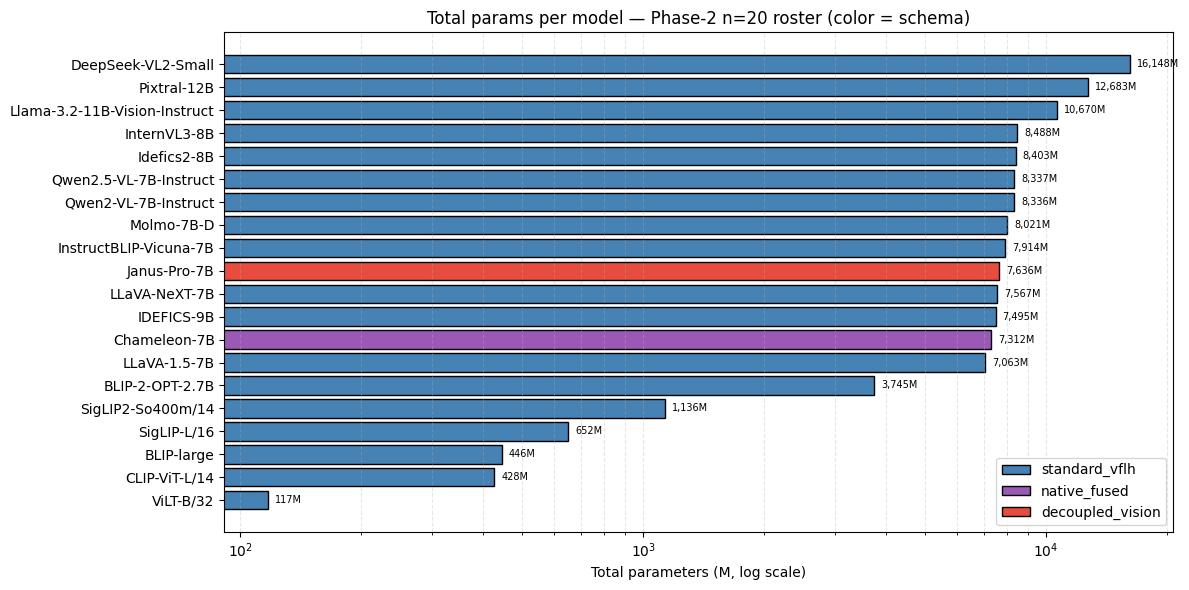

In [19]:
if results:
    plot_df = params_df.copy().sort_values('total_M').reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 6))
    schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
    bar_colors = [schema_colors.get(s, 'gray') for s in plot_df['schema']]
    bars = ax.barh(plot_df['name'], plot_df['total_M'], color=bar_colors, edgecolor='black')
    ax.set_xscale('log')
    ax.set_xlabel('Total parameters (M, log scale)')
    ax.set_title('Total params per model — Phase-2 n=20 roster (color = schema)')
    for bar, val in zip(bars, plot_df['total_M']):
        ax.annotate(f'{val:,.0f}M', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points', va='center', fontsize=7)
    from matplotlib.patches import Patch
    legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
    ax.legend(handles=legend_handles, loc='lower right')
    ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb02_total_params_bar.png', dpi=300, bbox_inches='tight')
    plt.show()

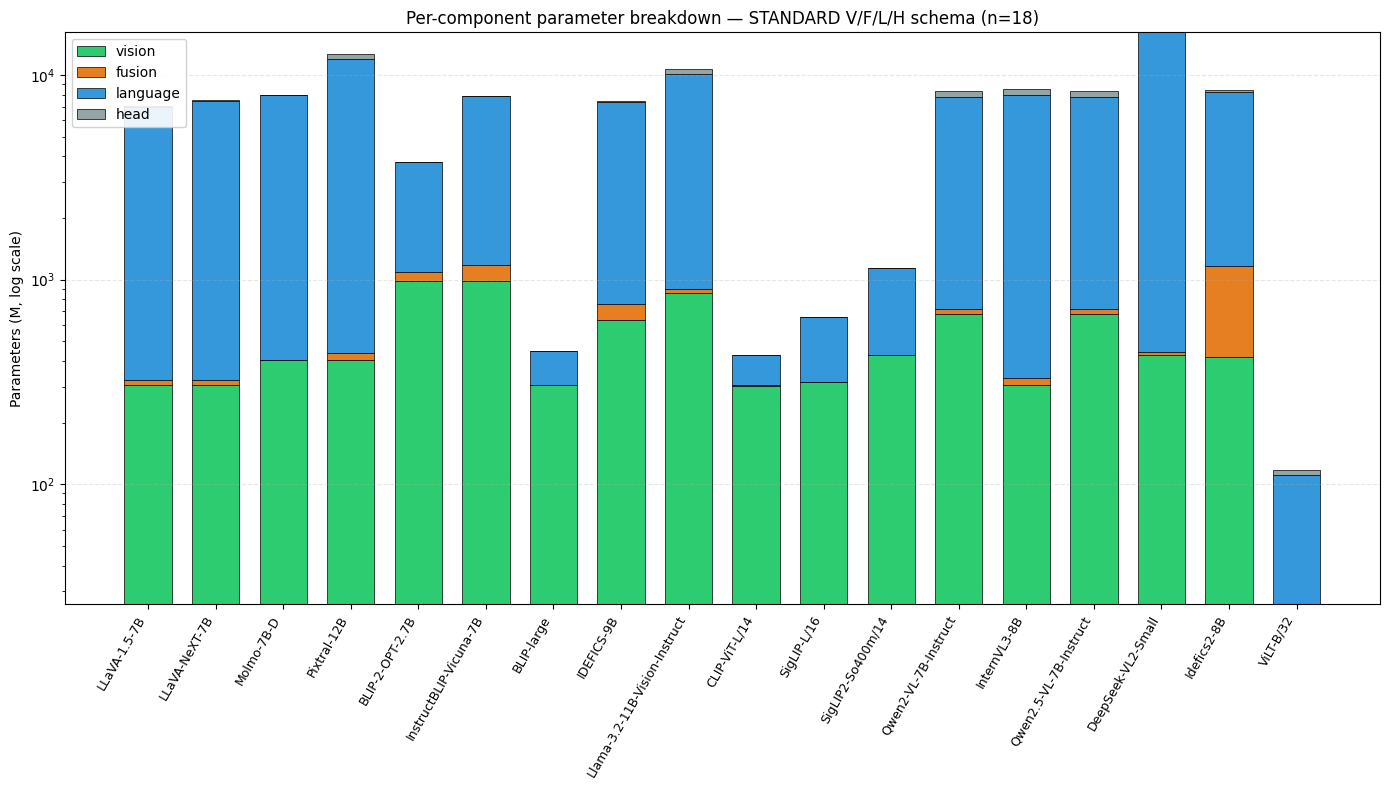

In [20]:
if results:
    sb_df = params_df[params_df['schema'] == 'standard_vflh'].copy().sort_values(['family', 'year', 'name']).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 8))
    x = np.arange(len(sb_df))
    width = 0.7
    colors = {'vision': '#2ECC71', 'fusion': '#E67E22', 'language': '#3498DB', 'head': '#95A5A6'}
    bottoms = np.zeros(len(sb_df))
    for cname in ['vision', 'fusion', 'language', 'head']:
        col = f'{cname}_total'
        if col not in sb_df.columns:
            continue
        vals = (sb_df[col].fillna(0) / 1e6).values
        ax.bar(x, vals, width=width, bottom=bottoms, color=colors[cname], edgecolor='black', linewidth=0.5, label=cname)
        bottoms += vals
    ax.set_xticks(x); ax.set_xticklabels(sb_df['name'], rotation=60, ha='right', fontsize=9)
    ax.set_ylabel('Parameters (M, log scale)')
    ax.set_yscale('log')
    ax.set_title(f'Per-component parameter breakdown — STANDARD V/F/L/H schema (n={len(sb_df)})')
    ax.legend(loc='upper left', framealpha=0.9)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb02_stacked_vflh_standard.png', dpi=300, bbox_inches='tight')
    plt.show()

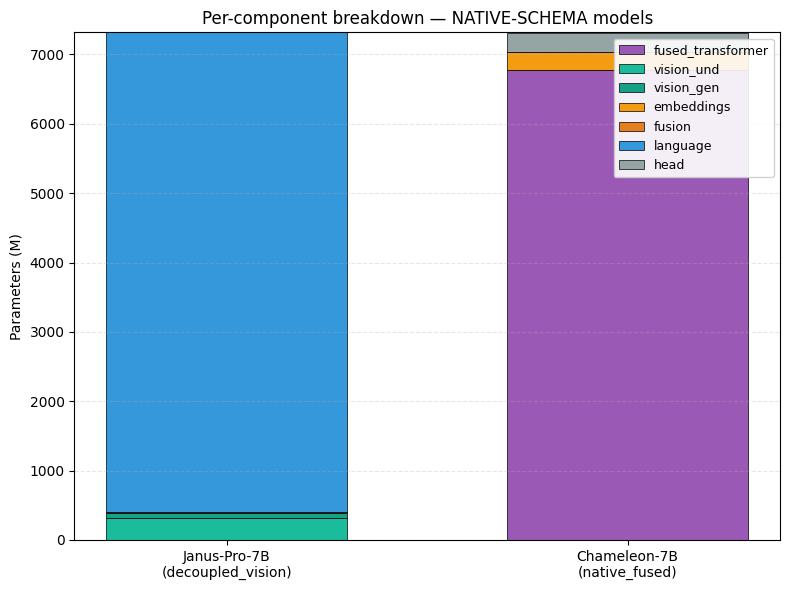

In [21]:
if results:
    native_df = params_df[params_df['schema'].isin(['native_fused', 'decoupled_vision'])].copy().sort_values(['schema', 'name']).reset_index(drop=True)
    if len(native_df) == 0:
        print('No native-schema models in the result set.')
    else:
        fig, ax = plt.subplots(figsize=(8, 6))
        x = np.arange(len(native_df))
        width = 0.6
        native_palette = {
            'fused_transformer': '#9B59B6', 'vision_und': '#1ABC9C', 'vision_gen': '#16A085',
            'embeddings': '#F39C12', 'fusion': '#E67E22', 'language': '#3498DB', 'head': '#95A5A6',
        }
        bottoms = np.zeros(len(native_df))
        for cname in ['fused_transformer', 'vision_und', 'vision_gen', 'embeddings', 'fusion', 'language', 'head']:
            col = f'{cname}_total'
            if col not in native_df.columns: continue
            vals = (native_df[col].fillna(0) / 1e6).values
            if vals.sum() == 0: continue
            ax.bar(x, vals, width=width, bottom=bottoms, color=native_palette.get(cname, 'gray'), edgecolor='black', linewidth=0.5, label=cname)
            bottoms += vals
        ax.set_xticks(x)
        ax.set_xticklabels([f'{n}\n({s})' for n, s in zip(native_df['name'], native_df['schema'])], fontsize=10)
        ax.set_ylabel('Parameters (M)')
        ax.set_title('Per-component breakdown — NATIVE-SCHEMA models')
        ax.legend(loc='upper right', framealpha=0.9, fontsize=9)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb02_stacked_native.png', dpi=300, bbox_inches='tight')
        plt.show()

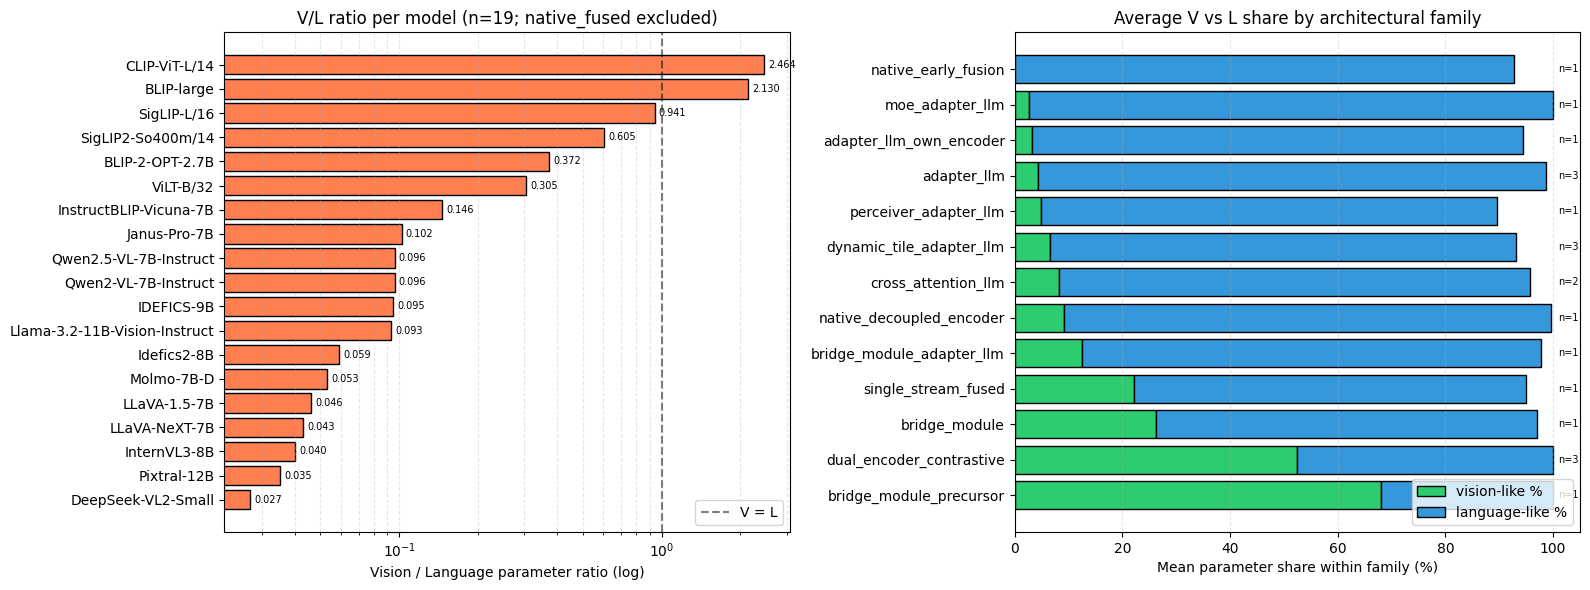

In [22]:
if results:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    rdf = params_df.dropna(subset=['v_to_l_ratio']).copy()
    rdf = rdf[rdf['v_to_l_ratio'] > 0].sort_values('v_to_l_ratio')
    bars = axes[0].barh(rdf['name'], rdf['v_to_l_ratio'], color='coral', edgecolor='black')
    axes[0].axvline(1.0, color='black', linestyle='--', alpha=0.5, label='V = L')
    axes[0].set_xscale('log')
    axes[0].set_xlabel('Vision / Language parameter ratio (log)')
    axes[0].set_title(f'V/L ratio per model (n={len(rdf)}; native_fused excluded)')
    axes[0].legend()
    axes[0].grid(True, which='both', axis='x', linestyle='--', alpha=0.3)
    for bar, val in zip(bars, rdf['v_to_l_ratio']):
        axes[0].annotate(f'{val:.3f}', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                         xytext=(3, 0), textcoords='offset points', va='center', fontsize=7)
    fam_summary = params_df.groupby('family').agg(
        n=('name', 'count'),
        avg_vision_pct=('vision_pct', 'mean'),
        avg_language_pct=('language_pct', 'mean'),
    ).sort_values('avg_vision_pct', ascending=False)
    axes[1].barh(fam_summary.index, fam_summary['avg_vision_pct'], color='#2ECC71', edgecolor='black', label='vision-like %')
    axes[1].barh(fam_summary.index, fam_summary['avg_language_pct'], left=fam_summary['avg_vision_pct'],
                 color='#3498DB', edgecolor='black', label='language-like %')
    axes[1].set_xlim(0, 105)
    axes[1].set_xlabel('Mean parameter share within family (%)')
    axes[1].set_title('Average V vs L share by architectural family')
    axes[1].legend(loc='lower right')
    for i, (idx, row) in enumerate(fam_summary.iterrows()):
        axes[1].annotate(f'n={int(row["n"])}', xy=(101, i), va='center', fontsize=7)
    axes[1].grid(True, axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb02_vlratio_and_family.png', dpi=300, bbox_inches='tight')
    plt.show()

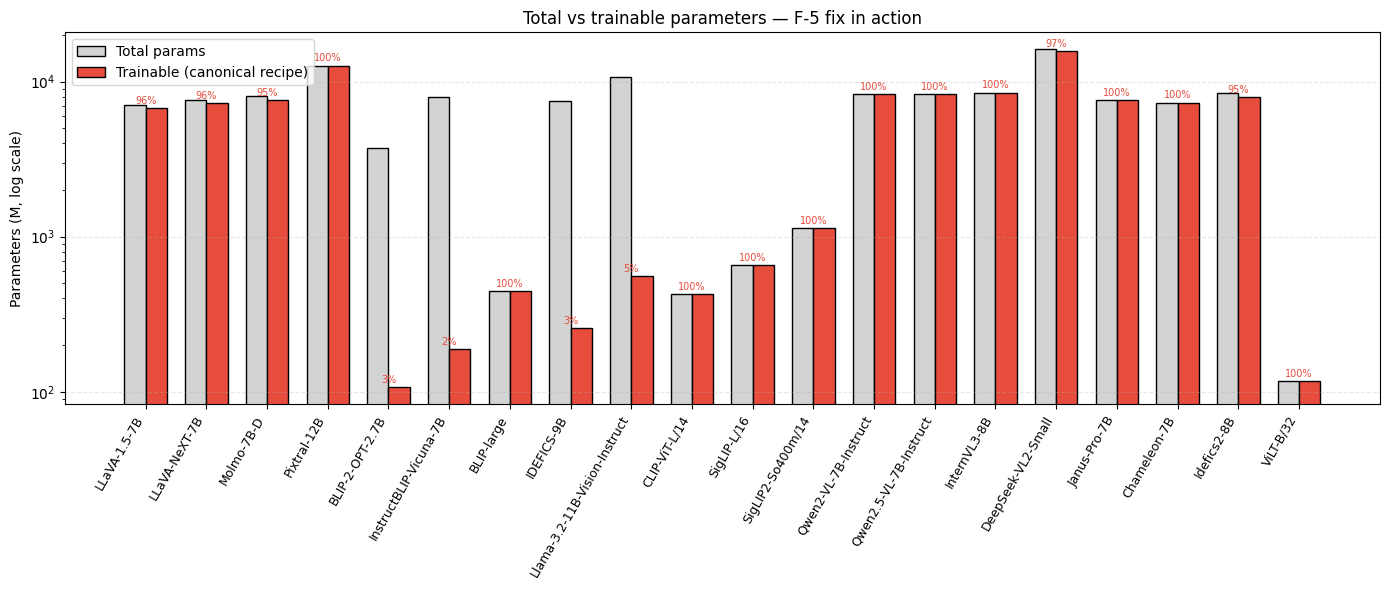

In [23]:
if results:
    sb_df = params_df.copy().sort_values(['family', 'year']).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(sb_df))
    width = 0.35
    ax.bar(x - width/2, sb_df['total_M'], width=width, color='lightgray', edgecolor='black', label='Total params')
    ax.bar(x + width/2, sb_df['trainable_total_M'], width=width, color='#E74C3C', edgecolor='black', label='Trainable (canonical recipe)')
    ax.set_yscale('log'); ax.set_xticks(x)
    ax.set_xticklabels(sb_df['name'], rotation=60, ha='right', fontsize=9)
    ax.set_ylabel('Parameters (M, log scale)')
    ax.set_title('Total vs trainable parameters — F-5 fix in action')
    ax.legend(loc='upper left')
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    for i, (_, row) in enumerate(sb_df.iterrows()):
        ax.annotate(f'{row["trainable_pct"]:.0f}%', xy=(i, max(row['trainable_total_M'], 0.01)),
                    xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7, color='#E74C3C')
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb02_trainable_vs_total.png', dpi=300, bbox_inches='tight')
    plt.show()

---
## 9. Per-family summary

In [24]:
if results:
    family_summary = params_df.groupby('family').agg(
        n_models       = ('name', 'count'),
        avg_total_M    = ('total_M', 'mean'),
        avg_vision_pct = ('vision_pct', 'mean'),
        avg_fusion_pct = ('fusion_pct', 'mean'),
        avg_language_pct = ('language_pct', 'mean'),
        avg_v_to_l_ratio = ('v_to_l_ratio', 'mean'),
        avg_trainable_pct = ('trainable_pct', 'mean'),
        models = ('name', lambda s: ', '.join(s)),
    ).round(1).sort_values('avg_vision_pct', ascending=False)
family_summary if results else None

,n_models,avg_total_M,avg_vision_pct,avg_fusion_pct,avg_language_pct,avg_v_to_l_ratio,avg_trainable_pct,models
family,,,,,,,,
bridge_module_precursor,1,446.3,68.0,0.0,32.0,2.1,100.0,BLIP-large
dual_encoder_contrastive,3,738.7,52.4,0.1,47.5,1.3,100.0,"CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14"
bridge_module,1,3744.7,26.3,2.8,70.8,0.4,2.9,BLIP-2-OPT-2.7B
single_stream_fused,1,117.0,22.2,0.0,72.7,0.3,100.0,ViLT-B/32
bridge_module_adapter_llm,1,7913.7,12.5,2.3,85.2,0.1,2.4,InstructBLIP-Vicuna-7B
native_decoupled_encoder,1,7635.9,9.2,0.3,90.5,0.1,100.0,Janus-Pro-7B
cross_attention_llm,2,9082.7,8.2,1.0,87.4,0.1,4.3,"IDEFICS-9B, Llama-3.2-11B-Vision-Instruct"
dynamic_tile_adapter_llm,3,8386.9,6.6,0.4,86.4,0.1,100.0,"Qwen2-VL-7B-Instruct, Qwen2.5-VL-7B-Instruct, ..."
perceiver_adapter_llm,1,8402.8,5.0,8.8,84.6,0.1,95.0,Idefics2-8B


---
## 10. Failures + save

In [25]:
if failures:
    failures_df = pd.DataFrame(failures)
    print(f'{len(failures)} failures:')
    failures_df
else:
    print('No failures — all models succeeded.')

No failures — all models succeeded.


In [26]:
if not results:
    print('Nothing to save — no successful results.')
else:
    csv_master = MEASUREMENT_DIR / 'nb02_parameter_summary.csv'
    csv_family = MEASUREMENT_DIR / 'nb02_family_summary.csv'
    csv_wide   = MEASUREMENT_DIR / 'nb02_parameter_wide.csv'
    params_df.to_csv(csv_master, index=False)
    family_summary.to_csv(csv_family)
    wide_view.to_csv(csv_wide, index=False)
    print(f'Saved: {csv_master}')
    print(f'Saved: {csv_family}')
    print(f'Saved: {csv_wide}')
    print(f'Per-model JSONs: {MEASUREMENT_DIR}/<hf_id>.json (incremental merge — preserves FLOPs/memory if measured)')
    print(f'Logs (only for actually-audited models): {LOG_DIR}/')
    print(f'Figures: {FIG_DIR}/nb02_*.png')
    print()
    if skipped:
        print(f'Models loaded from existing JSON (no model load/download): {len(skipped)}')
        for n in skipped[:10]:
            print(f'  • {n}')
        if len(skipped) > 10:
            print(f'  … and {len(skipped)-10} more')

Saved: /workspace/code_active/outputs/measurements/nb02_parameter_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb02_family_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb02_parameter_wide.csv
Per-model JSONs: /workspace/code_active/outputs/measurements/<hf_id>.json (incremental merge — preserves FLOPs/memory if measured)
Logs (only for actually-audited models): /workspace/code_active/outputs/logs/
Figures: /workspace/code_active/outputs/figures/nb02_*.png

Models loaded from existing JSON (no model load/download): 14
  • CLIP-ViT-L/14
  • SigLIP-L/16
  • BLIP-large
  • BLIP-2-OPT-2.7B
  • InstructBLIP-Vicuna-7B
  • LLaVA-1.5-7B
  • LLaVA-NeXT-7B
  • IDEFICS-9B
  • Idefics2-8B
  • ViLT-B/32
  … and 4 more


---
## Next steps

* Re-running this notebook will be near-instant (just reads JSONs + builds figures) as long as `SKIP_IF_MEASURED=True` and no `FORCE_RERUN` entries.
* To re-measure a single model (e.g. after a `vlm_audit/` patch), set `FORCE_RERUN = ['<model name>']` in §1 and re-run cells from §6 onwards.
* To wipe and re-measure everything: set `SKIP_IF_MEASURED = False` in §1, OR delete the per-model JSON in `outputs/measurements/`.
* Continue to `03_flops_analysis.ipynb` for FLOPs measurements (merges into the same per-model JSONs).

*End of notebook 02 (v4 — 2026-05-22). Changes from v3: skip-if-measured + upfront cache/measurement audit.*